In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = 'Apple SD Gothic Neo'

### 검증용/학습용 데이터 분리

In [4]:
df = pd.read_csv("../data/1차 전처리(센서 제거)/train1_sens_filter.csv", index_col=0)

rng = np.random.default_rng(42)                 # 시드 고정 → 누가 돌려도 같은 분할
engines = np.sort(df["engine_id"].unique())
replay_ids = np.sort(rng.choice(engines, size=20, replace=False))

split = pd.DataFrame({"engine_id": engines})
split["role"] = np.where(split["engine_id"].isin(replay_ids), "replay", "dev")

# 개발용 80대에 폴드 번호 부여 (엔진 단위)
dev_ids = split.loc[split.role == "dev", "engine_id"].to_numpy()
fold_of = {e: i % 5 for i, e in enumerate(rng.permutation(dev_ids))}
split["fold"] = split["engine_id"].map(fold_of)   # replay는 NaN

Path("../data/split").mkdir(exist_ok=True)
split.to_csv("../data/split/engine_split.csv", index=False)

# 확인: 두 그룹의 수명 분포가 크게 다르지 않은지
life = df.groupby("engine_id")["cycle"].max()
print(split.role.value_counts())
print(life.groupby(split.set_index("engine_id")["role"]).describe().round(1))

role
dev       80
replay    20
Name: count, dtype: int64
        count   mean   std    min    25%    50%    75%    max
role                                                         
dev      80.0  204.9  44.5  128.0  177.8  199.0  223.8  341.0
replay   20.0  212.0  53.9  150.0  176.0  196.5  237.2  362.0


### 라벨 및 평가 함수

In [5]:
def cap_rul(rul, cap):
    """구간 선형 라벨: 상한 이상은 cap으로 자름 (학습 라벨 전용)"""
    return np.minimum(rul, cap)

def phm_score(y_true, y_pred):
    """PHM08 비대칭 점수. d>0(늦은 예측)이 더 큰 벌점. 낮을수록 좋음"""
    d = np.asarray(y_pred) - np.asarray(y_true)
    return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

def evaluate(y_true_raw, y_pred, eval_max=115):
    """채점은 상한을 씌우지 않은 실제 RUL로, 세 상한 후보가 공통으로 다루는 RUL<=115 구간만"""
    y_true_raw, y_pred = np.asarray(y_true_raw), np.asarray(y_pred)
    m = y_true_raw <= eval_max
    yt, yp = y_true_raw[m], y_pred[m]
    return {"rmse": np.sqrt(np.mean((yp - yt) ** 2)),
            "phm_mean": phm_score(yt, yp) / len(yt),   # 행 수가 폴드마다 달라 평균으로
            "late_ratio": np.mean(yp > yt)}            # 늦게 예측한 비율

### 평균 예측 베이스라인(최소 기준)

In [7]:
dev = df.merge(split, on="engine_id").query("role == 'dev'")

rows = []
for cap in [115, 130, 150]:
    for k in range(5):
        tr, va = dev[dev.fold != k], dev[dev.fold == k]
        pred = np.full(len(va), cap_rul(tr["RUL"], cap).mean())   # 학습 폴드 라벨 평균
        rows.append({"cap": cap, "fold": k, **evaluate(va["RUL"], pred)})
base = pd.DataFrame(rows)
base.groupby("cap")[["rmse", "phm_mean", "late_ratio"]].agg(["mean", "std"]).round(2)

rmse       phm_mean        late_ratio      
      mean   std     mean    std       mean   std
cap                                              
115  41.75  0.26   345.12  14.76       0.71  0.00
130  45.59  0.38   628.01  34.20       0.77  0.00
150  50.09  0.54  1182.12  84.00       0.82  0.01

>  최소 평가 기준 만듬   
> - 학습용 엔진들의 RUL 상한(무릎값평균 : 115)을 적용한 뒤, 그 값을 평균냄 = 각 행의 평균 RUL은 82사이클
> - 검증용 엔진들의 상한은 그대로 82로 결정   
> - 그때 검증용 엔진의 RMSE값은 41.75 = 41사이클.  
이때 RMSE값의 의미 : 41사이클의 크기만큼 오차가 있음. 
예를 들어 5-4-3-2-1의 실제 RUL값을 7-6-5-4-3 으로 예측했다면 오차는 2-2-2-2-2, 2+2+2+2+2/5 = 2이고, 제곱근을 씌워서 루트2가 됨.

In [8]:
SENSORS = ["s2","s3","s4","s7","s8","s11","s12","s13","s15","s17","s20","s21"]

def make_features(hist, N=20, sensors=SENSORS):
    """
    hist: engine_id, cycle, 센서 열을 가진 DataFrame (한 엔진 또는 여러 엔진)
    반환: 각 행마다 '그 시점까지의 최근 N사이클'로만 계산한 특징 (과거만 사용)
      - {s}_mean: 최근 N사이클 평균
      - {s}_slope: 최근 N사이클 기울기 (사이클당 변화량)
    """
    hist = hist.sort_values(["engine_id", "cycle"])
    g = hist.groupby("engine_id", sort=False)
    t = hist["cycle"].astype(float)

    def rmean(s):  # 엔진별 rolling 평균, 초반엔 있는 만큼만
        return s.groupby(hist["engine_id"], sort=False) \
                .transform(lambda x: x.rolling(N, min_periods=1).mean())

    mt, mtt = rmean(t), rmean(t * t)
    var_t = mtt - mt ** 2                       # 윈도우 안 사이클의 분산

    out = hist[["engine_id", "cycle"]].copy()
    for s in sensors:
        x = hist[s].astype(float)
        mx, mtx = rmean(x), rmean(t * x)
        out[f"{s}_mean"] = mx
        # 최소제곱 기울기 = cov(t,x)/var(t). 첫 사이클은 var=0이라 0으로 처리
        out[f"{s}_slope"] = np.where(var_t > 1e-9, (mtx - mt * mx) / var_t.where(var_t > 1e-9, 1), 0.0)
    return out

In [9]:
N = 20
batch = make_features(df, N=N)

# 실시간 흉내: 엔진 1번의 각 사이클마다 '최근 N줄 버퍼'만 넣고 마지막 줄을 꺼냄
e1 = df[df.engine_id == 1].sort_values("cycle")
stream = pd.concat([make_features(e1.iloc[max(0, i - N + 1): i + 1], N=N).tail(1)
                    for i in range(len(e1))])

feat_cols = [c for c in batch.columns if c.endswith(("_mean", "_slope"))]
b1 = batch[batch.engine_id == 1][feat_cols].to_numpy()
print("최대 차이:", np.abs(b1 - stream[feat_cols].to_numpy()).max())
print("일치:", np.allclose(b1, stream[feat_cols].to_numpy()))

최대 차이: 3.5012127745648325e-12
일치: True


### 선형회귀 베이스라인

센서별 열화 곡선은 지수함수를 나타내기 때문에 비선형성을 가짐. 따라서 선형 회귀는 적합한 선이 아님.    
베이스라인을 정하는 것이기 때문에 간단한 선형회귀로 일단 표현.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

feats = make_features(df, N=20).merge(df[["engine_id", "cycle", "RUL"]], on=["engine_id", "cycle"])
feats = feats.merge(split, on="engine_id").query("role == 'dev'")
X_cols = [c for c in feats.columns if c.endswith(("_mean", "_slope"))]

rows = []
for cap in [115, 130, 150]:
    for k in range(5):
        tr, va = feats[feats.fold != k], feats[feats.fold == k]
        model = make_pipeline(StandardScaler(), LinearRegression())
        model.fit(tr[X_cols], cap_rul(tr["RUL"], cap))      # 학습 라벨만 상한 적용
        pred = np.clip(model.predict(va[X_cols]), 0, None)  # RUL은 음수가 될 수 없음
        rows.append({"cap": cap, "fold": k, **evaluate(va["RUL"], pred)})
lin = pd.DataFrame(rows)
lin.groupby("cap")[["rmse", "phm_mean", "late_ratio"]].agg(["mean", "std"]).round(2)

rmse       phm_mean       late_ratio      
      mean   std     mean   std       mean   std
cap                                             
115  18.56  1.40     7.25  1.56       0.67  0.08
130  21.01  1.68    12.29  2.91       0.72  0.07
150  24.59  2.07    24.34  6.28       0.75  0.06

rmse값은 평균제곱근 오차 -> 늦은 예측에 큰 벌점을 주는 시스탬(값이 크면 제곱근을 씌워서 더 커짐)

1. 82를 기준으로 

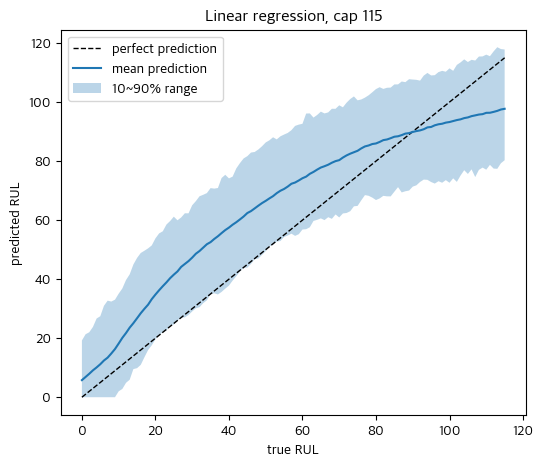

In [11]:
cap = 115
oof = []                                   # 각 행을 '자기가 빠진 폴드의 모델'로 예측한 값
for k in range(5):
    tr, va = feats[feats.fold != k], feats[feats.fold == k]
    m = make_pipeline(StandardScaler(), LinearRegression()).fit(tr[X_cols], cap_rul(tr["RUL"], cap))
    oof.append(va.assign(pred=np.clip(m.predict(va[X_cols]), 0, None)))
oof = pd.concat(oof).query("RUL <= 115")

g = oof.groupby("RUL")["pred"]
plt.figure(figsize=(6, 5))
plt.plot([0, 115], [0, 115], "k--", lw=1, label="perfect prediction")
plt.plot(g.mean().index, g.mean(), label="mean prediction")
plt.fill_between(g.mean().index, g.quantile(.1), g.quantile(.9), alpha=.3, label="10~90% range")
plt.xlabel("true RUL"); plt.ylabel("predicted RUL"); plt.legend(); plt.title("Linear regression, cap 115")
plt.show()